In [1]:
# تمرین:
# دیتاست را بخوانید و تحلیل اولیه کنید
#‌ چک کنید مقدار خالی دارد یا نه
#‌ چک کنید مقدار تکراری دارد یا نه
# مدل درخت تصمیم را برای دیتاست آموزش بدید
# در نهایت دقت یا خطا را بفرستید
# دقت -> کلسیفیکیشن
# خطا -> رگرسیون

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn import linear_model
from sklearn import ensemble
from sklearn import tree
from sklearn import metrics

In [3]:
data = pd.read_csv("health_lifestyle_dataset.csv")
data

,id,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
0,1,56,Male,20.5,4198,3.9,3.4,1602,0,0,97,161,111,240,0,0
1,2,69,Female,33.3,14359,9.0,4.7,2346,0,1,68,116,65,207,0,0
2,3,46,Male,31.6,1817,6.6,4.2,1643,0,1,90,123,99,296,0,0
3,4,32,Female,38.2,15772,3.6,2.0,2460,0,0,71,165,95,175,0,0
4,5,60,Female,33.6,6037,3.8,4.0,3756,0,1,98,139,61,294,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,53,Male,33.1,4726,3.9,2.0,3118,0,1,56,105,76,282,0,0
99996,99997,22,Male,35.1,11554,4.5,3.1,1967,0,0,51,149,77,192,0,0
99997,99998,37,Male,18.9,3924,3.8,1.0,2328,0,0,69,92,117,218,0,0
99998,99999,72,Female,27.8,16110,5.6,0.8,3093,0,0,93,164,72,188,0,0


In [4]:
data = data.drop("id",axis=1)
data

,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk
0,56,Male,20.5,4198,3.9,3.4,1602,0,0,97,161,111,240,0,0
1,69,Female,33.3,14359,9.0,4.7,2346,0,1,68,116,65,207,0,0
2,46,Male,31.6,1817,6.6,4.2,1643,0,1,90,123,99,296,0,0
3,32,Female,38.2,15772,3.6,2.0,2460,0,0,71,165,95,175,0,0
4,60,Female,33.6,6037,3.8,4.0,3756,0,1,98,139,61,294,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,53,Male,33.1,4726,3.9,2.0,3118,0,1,56,105,76,282,0,0
99996,22,Male,35.1,11554,4.5,3.1,1967,0,0,51,149,77,192,0,0
99997,37,Male,18.9,3924,3.8,1.0,2328,0,0,69,92,117,218,0,0
99998,72,Female,27.8,16110,5.6,0.8,3093,0,0,93,164,72,188,0,0


In [5]:
data.shape

(100000, 15)

In [6]:
data.columns

Index(['age', 'gender', 'bmi', 'daily_steps', 'sleep_hours', 'water_intake_l',
       'calories_consumed', 'smoker', 'alcohol', 'resting_hr', 'systolic_bp',
       'diastolic_bp', 'cholesterol', 'family_history', 'disease_risk'],
      dtype='object')

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   age                100000 non-null  int64  
 1   gender             100000 non-null  object 
 2   bmi                100000 non-null  float64
 3   daily_steps        100000 non-null  int64  
 4   sleep_hours        100000 non-null  float64
 5   water_intake_l     100000 non-null  float64
 6   calories_consumed  100000 non-null  int64  
 7   smoker             100000 non-null  int64  
 8   alcohol            100000 non-null  int64  
 9   resting_hr         100000 non-null  int64  
 10  systolic_bp        100000 non-null  int64  
 11  diastolic_bp       100000 non-null  int64  
 12  cholesterol        100000 non-null  int64  
 13  family_history     100000 non-null  int64  
 14  disease_risk       100000 non-null  int64  
dtypes: float64(3), int64(11), object(1)
memory usage: 11

In [8]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,48.525990,17.886768,18.0,33.0,48.0,64.0,79.0
bmi,100000.0,29.024790,6.352666,18.0,23.5,29.0,34.5,40.0
daily_steps,100000.0,10479.870290,5483.632360,1000.0,5729.0,10468.0,15229.0,19999.0
sleep_hours,100000.0,6.491784,2.021922,3.0,4.7,6.5,8.2,10.0
water_intake_l,100000.0,2.751496,1.297338,0.5,1.6,2.8,3.9,5.0
calories_consumed,100000.0,2603.341200,807.288563,1200.0,1906.0,2603.0,3299.0,3999.0
smoker,100000.0,0.200940,0.400705,0.0,0.0,0.0,0.0,1.0
alcohol,100000.0,0.300020,0.458269,0.0,0.0,0.0,1.0,1.0
resting_hr,100000.0,74.457420,14.423715,50.0,62.0,74.0,87.0,99.0
systolic_bp,100000.0,134.580630,25.951530,90.0,112.0,135.0,157.0,179.0


In [9]:
print(data["alcohol"].value_counts())
print("------------------")
print(data["smoker"].value_counts())
print("------------------")
print(data["disease_risk"].value_counts())
print("------------------")

alcohol
0    69998
1    30002
Name: count, dtype: int64
------------------
smoker
0    79906
1    20094
Name: count, dtype: int64
------------------
disease_risk
0    75179
1    24821
Name: count, dtype: int64
------------------


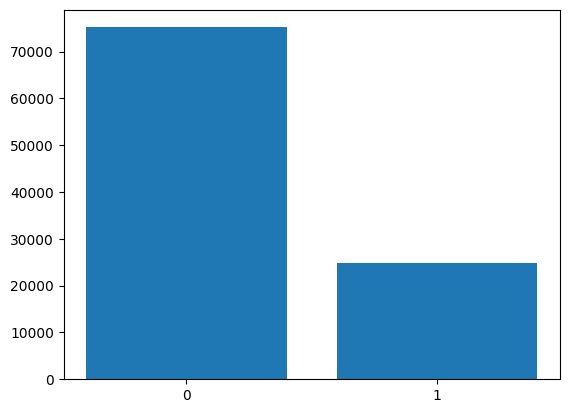

In [10]:
idx = [0 , 1]
count = data['disease_risk'].value_counts()
plt.bar(idx , count)
plt.xticks(idx)
plt.show()

In [11]:
data.isnull().sum().sum()

0

In [12]:
data.duplicated().sum()

0

In [13]:
data["gender"].value_counts()

gender
Male      50132
Female    49868
Name: count, dtype: int64

In [14]:
data["gender"] = data["gender"].replace({"Male":0,"Female":1})
data["gender"] = data["gender"].astype("int")
data["gender"].value_counts()

/var/folders/rw/j7c6vw4s1hl90fjq5cy_xp_80000gn/T/ipykernel_14617/2545973746.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data["gender"] = data["gender"].replace({"Male":0,"Female":1})


gender
0    50132
1    49868
Name: count, dtype: int64

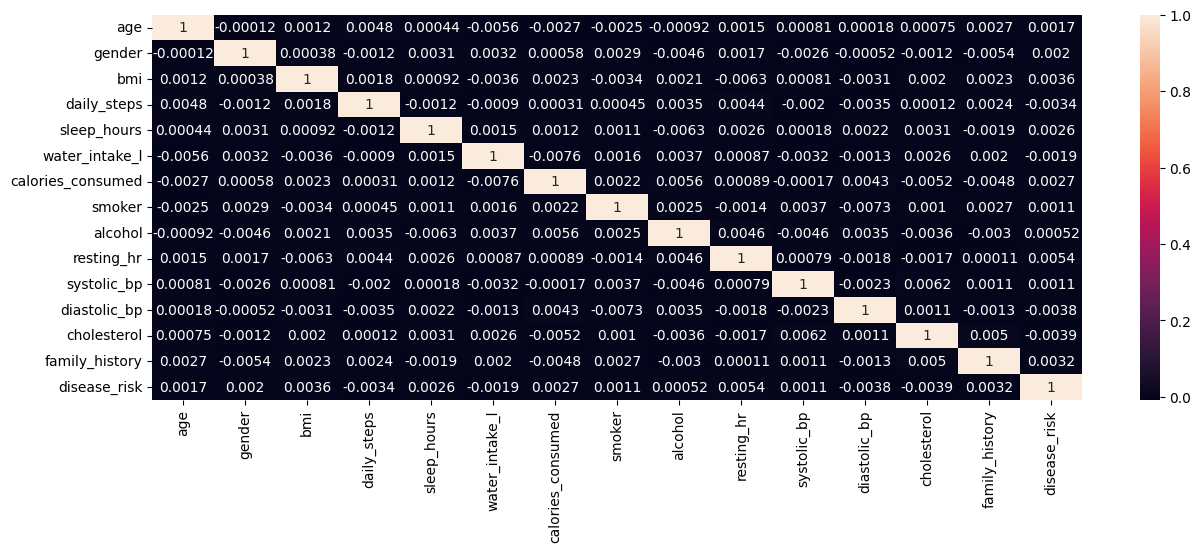

In [15]:
plt.figure(figsize=(15,5))
sns.heatmap(data.corr(),annot=True)
plt.show()

In [16]:
x = data.drop("disease_risk",axis=1)
y = data["disease_risk"]
x_train , x_test , y_train , y_test = train_test_split(
    x , y , test_size=0.2 , random_state=42
)
x_train.shape , x_test.shape , y_train.shape , y_test.shape

((80000, 14), (20000, 14), (80000,), (20000,))

In [17]:
model_tree = tree.DecisionTreeClassifier(max_depth=4)
model_tree.fit(x_train,y_train)
y_pred_tree = model_tree.predict(x_test)
metrics.accuracy_score(y_test , y_pred_tree)*100

75.2

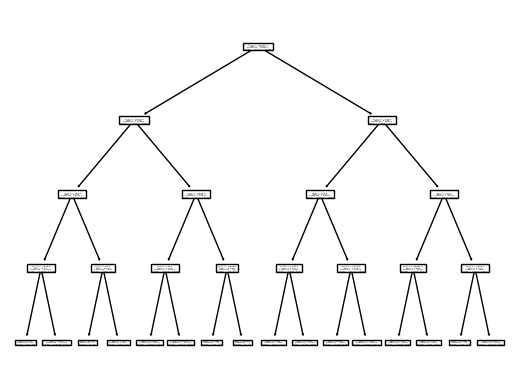

In [18]:
tree.plot_tree(model_tree)
plt.show()

In [19]:
model_forest = ensemble.RandomForestClassifier(n_estimators=50)
model_forest.fit(x_train,y_train)
y_pred_forest = model_forest.predict(x_test)
metrics.accuracy_score(y_test , y_pred_forest)*100

75.165